In [1]:
# In Google Colab/Jupyter, run this install line if dependencies are missing:
%pip install -q stim pymatching scikit-learn numpy matplotlib
import numpy as np
import matplotlib.pyplot as plt
import stim
import pymatching

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

print("Libraries imported successfully.")
print("Stim version:", stim.__version__)


Libraries imported successfully.
Stim version: 1.16.0


In [2]:
SEED = 42
DISTANCE = 3
ROUNDS = 3
TRAINING_NOISE_RATE = 0.005
DATASET_SHOTS = 50000
TEST_SIZE = 0.20

ERROR_RATES = [0.001, 0.003, 0.005, 0.01, 0.02]
SWEEP_SHOTS = 20000

np.random.seed(SEED)

print(f"Code distance: {DISTANCE}")
print(f"Measurement rounds: {ROUNDS}")
print(f"Training-data physical error rate: {TRAINING_NOISE_RATE:.3%}")
print(f"Dataset shots: {DATASET_SHOTS}")
print(f"Random seed: {SEED}")


Code distance: 3
Measurement rounds: 3
Training-data physical error rate: 0.500%
Dataset shots: 50000
Random seed: 42


In [3]:
def make_surface_code_circuit(error_probability, distance=DISTANCE, rounds=ROUNDS):
    """Build the noisy rotated surface-code X-memory circuit."""
    return stim.Circuit.generated(
        "surface_code:rotated_memory_x",
        distance=distance,
        rounds=rounds,
        after_clifford_depolarization=error_probability,
        before_round_data_depolarization=error_probability,
        after_reset_flip_probability=error_probability,
        before_measure_flip_probability=error_probability,
    )

circuit = make_surface_code_circuit(TRAINING_NOISE_RATE)

print("Number of physical qubits:", circuit.num_qubits)
print("Number of detectors:", circuit.num_detectors)
print("Number of logical observables:", circuit.num_observables)
print("Number of circuit ticks:", circuit.num_ticks)

if circuit.num_observables != 1:
    raise ValueError(
        f"This baseline expects one logical observable; found {circuit.num_observables}."
    )


Number of physical qubits: 26
Number of detectors: 24
Number of logical observables: 1
Number of circuit ticks: 21


In [4]:
sampler = circuit.compile_detector_sampler(seed=SEED)
syndromes, logical_outcomes = sampler.sample(
    shots=DATASET_SHOTS,
    separate_observables=True,
)

X = np.asarray(syndromes, dtype=np.uint8)
Y = np.asarray(logical_outcomes, dtype=np.uint8)

assert X.ndim == 2, "Detector features must be a 2D matrix."
assert Y.ndim == 2, "Observable outcomes must be a 2D matrix."
assert X.shape[0] == Y.shape[0], "Feature and label shot counts differ."
assert X.shape[1] == circuit.num_detectors, "Unexpected detector count."
assert Y.shape[1] == circuit.num_observables, "Unexpected observable count."
assert np.isin(X, [0, 1]).all(), "Detector features must be binary."
assert np.isin(Y, [0, 1]).all(), "Observable labels must be binary."

y = Y[:, 0].astype(np.uint8)

print("Feature matrix X:", X.shape)
print("Observable matrix Y:", Y.shape)
print("Logical-flip label shape:", y.shape)
print("Observed logical-flip fraction:", f"{y.mean():.4%}")
print("Label counts [0, 1]:", np.bincount(y, minlength=2))

if len(np.unique(y)) != 2:
    raise ValueError(
        "Only one target class was observed. Increase DATASET_SHOTS or inspect the circuit."
    )


Feature matrix X: (50000, 24)
Observable matrix Y: (50000, 1)
Logical-flip label shape: (50000,)
Observed logical-flip fraction: 10.3800%
Label counts [0, 1]: [44810  5190]


In [5]:
# One fixed, stratified split: 70% train, 15% validation, 15% test.
# The test set is held out until final evaluation.
from sklearn.model_selection import train_test_split

indices = np.arange(len(y))
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=y
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=y[temp_idx]
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]
Y_test = Y[test_idx]  # shape (test shots, 1)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)
assert not (set(train_idx) & set(val_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(val_idx) & set(test_idx))

print('Train:', X_train.shape, 'label counts:', np.bincount(y_train, minlength=2))
print('Validation:', X_val.shape, 'label counts:', np.bincount(y_val, minlength=2))
print('Test:', X_test.shape, 'label counts:', np.bincount(y_test, minlength=2))


Train: (35000, 24) label counts: [31367  3633]
Validation: (7500, 24) label counts: [6721  779]
Test: (7500, 24) label counts: [6722  778]


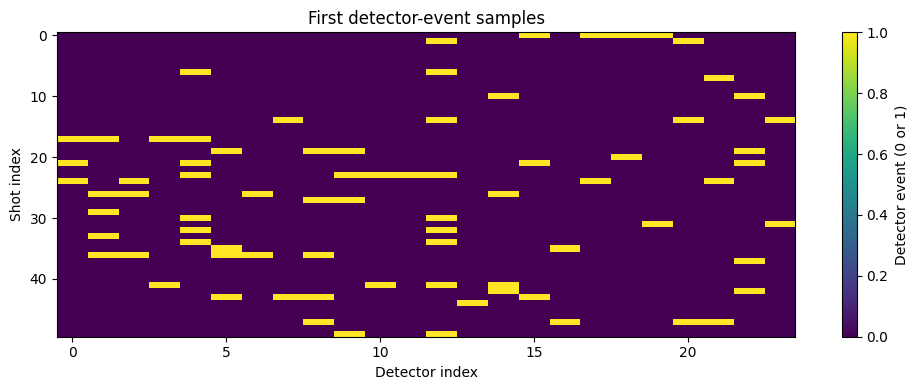

Logical-observable target distribution:
  Label 0: 44810 shots (89.62%)
  Label 1: 5190 shots (10.38%)


In [6]:
plt.figure(figsize=(10, 4))
plt.imshow(X[:min(50, len(X))], aspect="auto", interpolation="nearest")
plt.xlabel("Detector index")
plt.ylabel("Shot index")
plt.title("First detector-event samples")
plt.colorbar(label="Detector event (0 or 1)")
plt.tight_layout()
plt.show()

labels, counts = np.unique(y, return_counts=True)
print("Logical-observable target distribution:")
for label, count in zip(labels, counts):
    print(f"  Label {label}: {count} shots ({count / len(y):.2%})")


In [7]:
dem = circuit.detector_error_model(decompose_errors=True)
mwpm_decoder = pymatching.Matching.from_detector_error_model(dem)

mwpm_pred = np.asarray(
    mwpm_decoder.decode_batch(X_test),
    dtype=np.uint8,
).reshape(Y_test.shape)

assert mwpm_pred.shape == Y_test.shape
print("MWPM decoder built.")
print("MWPM prediction shape:", mwpm_pred.shape)
print("Actual observable shape:", Y_test.shape)

MWPM decoder built.
MWPM prediction shape: (7500, 1)
Actual observable shape: (7500, 1)


In [8]:
ordinary_ml = LogisticRegression(
    max_iter=1000,
    class_weight=None,
    random_state=SEED,
)
ordinary_ml.fit(X_train, y_train)
ordinary_pred = ordinary_ml.predict(X_test).astype(np.uint8)

print("Ordinary Logistic Regression trained.")
print("Predictions shape:", ordinary_pred.shape)


Ordinary Logistic Regression trained.
Predictions shape: (7500,)


In [9]:
balanced_ml = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED,
)
balanced_ml.fit(X_train, y_train)
balanced_pred = balanced_ml.predict(X_test).astype(np.uint8)

print("Balanced Logistic Regression trained.")
print("Predictions shape:", balanced_pred.shape)


Balanced Logistic Regression trained.
Predictions shape: (7500,)


In [10]:
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train)
majority_pred = majority_model.predict(X_test).astype(np.uint8)

print("Majority-class baseline trained.")


Majority-class baseline trained.


In [11]:
def wilson_interval(successes, total, z=1.96):
    """95% Wilson score interval for a binomial proportion."""
    if total <= 0:
        raise ValueError("total must be positive")
    p_hat = successes / total
    denom = 1 + z**2 / total
    center = (p_hat + z**2 / (2 * total)) / denom
    half_width = (
        z * np.sqrt((p_hat * (1 - p_hat) / total) + z**2 / (4 * total**2))
        / denom
    )
    return max(0.0, center - half_width), min(1.0, center + half_width)


def evaluate_decoder(name, prediction, actual):
    """Report classification metrics and logical-decoding failure rate."""
    prediction = np.asarray(prediction).reshape(-1, 1)
    actual = np.asarray(actual).reshape(-1, 1)

    if prediction.shape != actual.shape:
        raise ValueError(
            f"{name}: prediction shape {prediction.shape} does not match "
            f"actual shape {actual.shape}."
        )

    failures = int(np.any(prediction != actual, axis=1).sum())
    total = len(actual)
    failure_rate = failures / total
    ci_low, ci_high = wilson_interval(failures, total)

    print(f"\n===== {name} =====")
    print(f"Logical failures: {failures}/{total}")
    print(f"Logical failure rate: {failure_rate:.3%}")
    print(f"Approx. 95% Wilson CI: [{ci_low:.3%}, {ci_high:.3%}]")
    print("Accuracy:", round(accuracy_score(actual.ravel(), prediction.ravel()), 4))
    print(
        "Balanced accuracy:",
        round(balanced_accuracy_score(actual.ravel(), prediction.ravel()), 4),
    )
    print("Confusion matrix [rows=true, columns=predicted]:")
    print(confusion_matrix(actual.ravel(), prediction.ravel(), labels=[0, 1]))
    return {
        "name": name,
        "failures": failures,
        "total": total,
        "failure_rate": failure_rate,
        "ci_low": ci_low,
        "ci_high": ci_high,
    }


In [12]:
actual_test = Y_test

results = []
results.append(evaluate_decoder("MWPM", mwpm_pred, actual_test))
results.append(evaluate_decoder("Ordinary Logistic Regression", ordinary_pred, actual_test))
results.append(evaluate_decoder("Balanced Logistic Regression", balanced_pred, actual_test))
results.append(evaluate_decoder("Majority-Class Baseline", majority_pred, actual_test))

print("\n===== SUMMARY =====")
for result in results:
    print(
        f"{result['name']}: {result['failures']}/{result['total']} "
        f"({result['failure_rate']:.3%}; "
        f"95% CI {result['ci_low']:.3%}–{result['ci_high']:.3%})"
    )

# Additional classification metrics for the two ML models.
for name, prediction in [
    ("Ordinary Logistic Regression", ordinary_pred),
    ("Balanced Logistic Regression", balanced_pred),
]:
    print(f"\nDetailed classification report — {name}")
    print(
        classification_report(
            y_test,
            prediction,
            labels=[0, 1],
            target_names=["No observable flip", "Observable flip"],
            zero_division=0,
        )
    )


===== MWPM =====
Logical failures: 144/7500
Logical failure rate: 1.920%
Approx. 95% Wilson CI: [1.633%, 2.256%]
Accuracy: 0.9808
Balanced accuracy: 0.9444
Confusion matrix [rows=true, columns=predicted]:
[[6657   65]
 [  79  699]]

===== Ordinary Logistic Regression =====
Logical failures: 806/7500
Logical failure rate: 10.747%
Approx. 95% Wilson CI: [10.066%, 11.468%]
Accuracy: 0.8925
Balanced accuracy: 0.5513
Confusion matrix [rows=true, columns=predicted]:
[[6600  122]
 [ 684   94]]

===== Balanced Logistic Regression =====
Logical failures: 1558/7500
Logical failure rate: 20.773%
Approx. 95% Wilson CI: [19.870%, 21.706%]
Accuracy: 0.7923
Balanced accuracy: 0.8171
Confusion matrix [rows=true, columns=predicted]:
[[5282 1440]
 [ 118  660]]

===== Majority-Class Baseline =====
Logical failures: 778/7500
Logical failure rate: 10.373%
Approx. 95% Wilson CI: [9.703%, 11.084%]
Accuracy: 0.8963
Balanced accuracy: 0.5
Confusion matrix [rows=true, columns=predicted]:
[[6722    0]
 [ 778   

In [13]:
mwpm_sweep_results = []

for p in ERROR_RATES:
    sweep_circuit = make_surface_code_circuit(p)
    sweep_sampler = sweep_circuit.compile_detector_sampler(seed=SEED)
    sweep_syndromes, sweep_observables = sweep_sampler.sample(
        shots=SWEEP_SHOTS,
        separate_observables=True,
    )

    sweep_syndromes = np.asarray(sweep_syndromes, dtype=np.uint8)
    sweep_observables = np.asarray(sweep_observables, dtype=np.uint8)

    sweep_dem = sweep_circuit.detector_error_model(decompose_errors=True)
    sweep_decoder = pymatching.Matching.from_detector_error_model(sweep_dem)

    sweep_predictions = np.asarray(
        sweep_decoder.decode_batch(sweep_syndromes),
        dtype=np.uint8,
    ).reshape(sweep_observables.shape)

    failures = int(np.any(sweep_predictions != sweep_observables, axis=1).sum())
    rate = failures / SWEEP_SHOTS
    ci_low, ci_high = wilson_interval(failures, SWEEP_SHOTS)

    mwpm_sweep_results.append(
        {
            "physical_error_rate": p,
            "failures": failures,
            "shots": SWEEP_SHOTS,
            "logical_failure_rate": rate,
            "ci_low": ci_low,
            "ci_high": ci_high,
        }
    )

    print(
        f"Physical error rate: {p:.3%} | "
        f"Logical failures: {failures}/{SWEEP_SHOTS} | "
        f"Logical failure rate: {rate:.3%} | "
        f"95% Wilson CI: [{ci_low:.3%}, {ci_high:.3%}]"
    )


Physical error rate: 0.100% | Logical failures: 15/20000 | Logical failure rate: 0.075% | 95% Wilson CI: [0.045%, 0.124%]
Physical error rate: 0.300% | Logical failures: 143/20000 | Logical failure rate: 0.715% | 95% Wilson CI: [0.607%, 0.842%]
Physical error rate: 0.500% | Logical failures: 368/20000 | Logical failure rate: 1.840% | 95% Wilson CI: [1.663%, 2.036%]
Physical error rate: 1.000% | Logical failures: 1363/20000 | Logical failure rate: 6.815% | 95% Wilson CI: [6.474%, 7.173%]
Physical error rate: 2.000% | Logical failures: 3700/20000 | Logical failure rate: 18.500% | 95% Wilson CI: [17.968%, 19.044%]


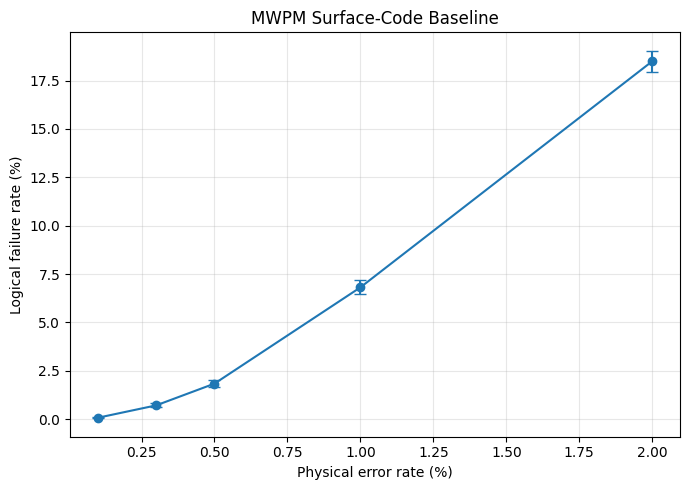

In [14]:
physical_rates_pct = [
    100 * item["physical_error_rate"] for item in mwpm_sweep_results
]
logical_rates_pct = [
    100 * item["logical_failure_rate"] for item in mwpm_sweep_results
]
lower_errors = [
    100 * (item["logical_failure_rate"] - item["ci_low"])
    for item in mwpm_sweep_results
]
upper_errors = [
    100 * (item["ci_high"] - item["logical_failure_rate"])
    for item in mwpm_sweep_results
]

plt.figure(figsize=(7, 5))
plt.errorbar(
    physical_rates_pct,
    logical_rates_pct,
    yerr=np.array([lower_errors, upper_errors]),
    marker="o",
    capsize=4,
)
plt.xlabel("Physical error rate (%)")
plt.ylabel("Logical failure rate (%)")
plt.title("MWPM Surface-Code Baseline")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:
import numpy as np

print("Feature shape:", X.shape)
print("Label shape:", y.shape)
print("Label counts:", np.unique(y, return_counts=True))
print("Label values:", np.unique(y))

assert len(X) == len(y)
assert set(np.unique(y)).issubset({0, 1})
assert len(np.unique(y)) == 2

Feature shape: (50000, 24)
Label shape: (50000,)
Label counts: (array([0, 1], dtype=uint8), array([44810,  5190]))
Label values: [0 1]


In [16]:
# Train the two logistic-regression baselines and the MLP on training data only.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

ordinary_ml = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight=None, random_state=SEED)
)
balanced_ml = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED)
)
mlp_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
        alpha=0.001, max_iter=500, early_stopping=False, random_state=SEED
    )
)

for name, model in [
    ('Ordinary Logistic Regression', ordinary_ml),
    ('Balanced Logistic Regression', balanced_ml),
    ('MLP', mlp_model),
]:
    model.fit(X_train, y_train)
    print(f'{name}: trained')


Ordinary Logistic Regression: trained
Balanced Logistic Regression: trained
MLP: trained


In [17]:
# Select the MLP probability threshold using validation data ONLY.
# Objective: minimize validation logical-observable mismatch rate.
thresholds = np.arange(0.10, 0.901, 0.025)
val_prob = mlp_model.predict_proba(X_val)[:, 1]
threshold_rows = []
for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(np.uint8)
    threshold_rows.append({
        'threshold': float(threshold),
        'validation_failures': int(np.sum(val_pred != y_val)),
        'validation_failure_rate': float(np.mean(val_pred != y_val)),
        'validation_balanced_accuracy': float(
            balanced_accuracy_score(y_val, val_pred)
        ),
    })

# Deterministic tie-break: among equal failure rates, choose threshold closest to 0.5.
best_row = min(threshold_rows, key=lambda r: (r['validation_failure_rate'], abs(r['threshold'] - 0.5)))
FINAL_THRESHOLD = best_row['threshold']
print('Validation-selected MLP threshold:', FINAL_THRESHOLD)
print('Validation failure rate at selected threshold:', f"{best_row['validation_failure_rate']:.4%}")
print('Validation balanced accuracy:', f"{best_row['validation_balanced_accuracy']:.4f}")


Validation-selected MLP threshold: 0.5499999999999999
Validation failure rate at selected threshold: 2.7600%
Validation balanced accuracy: 0.9069


In [18]:
# Decode the exact same held-out test detector samples with MWPM.
# Compare all decoders against the same observable labels from those samples.
dem = circuit.detector_error_model(decompose_errors=True)
mwpm_decoder = pymatching.Matching.from_detector_error_model(dem)
actual_test = np.asarray(Y_test, dtype=np.uint8).reshape(-1)
mwpm_test_pred = np.asarray(mwpm_decoder.decode_batch(X_test), dtype=np.uint8).reshape(-1)
lr_test_pred = ordinary_ml.predict(X_test).astype(np.uint8).reshape(-1)
lr_balanced_test_pred = balanced_ml.predict(X_test).astype(np.uint8).reshape(-1)
mlp_test_prob = mlp_model.predict_proba(X_test)[:, 1]
mlp_test_pred = (mlp_test_prob >= FINAL_THRESHOLD).astype(np.uint8)

assert all(len(p) == len(actual_test) for p in [mwpm_test_pred, lr_test_pred, lr_balanced_test_pred, mlp_test_pred])
assert np.array_equal(actual_test, y_test), 'Test labels do not match sampled observables.'
print('Held-out test shots:', len(actual_test))
print('All prediction arrays align with test labels.')


Held-out test shots: 7500
All prediction arrays align with test labels.


In [19]:
# Final held-out test comparison and confidence intervals.
import pandas as pd

predictions = {
    'MWPM': mwpm_test_pred,
    'Ordinary Logistic Regression': lr_test_pred,
    'Balanced Logistic Regression': lr_balanced_test_pred,
    'MLP (validation-tuned threshold)': mlp_test_pred,
}

comparison_rows = []
for name, pred in predictions.items():
    failures = int(np.sum(pred != actual_test))
    ci_low, ci_high = wilson_interval(failures, len(actual_test))
    comparison_rows.append({
        'Decoder': name,
        'Logical failures': failures,
        'Test shots': len(actual_test),
        'Logical failure rate': failures / len(actual_test),
        '95% CI low': ci_low,
        '95% CI high': ci_high,
        'Accuracy': accuracy_score(actual_test, pred),
        'Balanced accuracy': balanced_accuracy_score(actual_test, pred),
        'Confusion matrix [[TN, FP], [FN, TP]]': confusion_matrix(actual_test, pred, labels=[0, 1]).tolist(),
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
print('Important: compare logical failure rates; ML is not assumed to outperform MWPM.')


,Decoder,Logical failures,Test shots,Logical failure rate,95% CI low,95% CI high,Accuracy,Balanced accuracy,"Confusion matrix [[TN, FP], [FN, TP]]"
0,MWPM,144,7500,0.019200,0.016331,0.022561,0.980800,0.944394,"[[6657, 65], [79, 699]]"
1,Ordinary Logistic Regression,807,7500,0.107600,0.100787,0.114815,0.892400,0.551831,"[[6598, 124], [683, 95]]"
2,Balanced Logistic Regression,1558,7500,0.207733,0.198703,0.217063,0.792267,0.817054,"[[5282, 1440], [118, 660]]"
3,MLP (validation-tuned threshold),186,7500,0.024800,0.021516,0.028570,0.975200,0.915128,"[[6661, 61], [125, 653]]"


Important: compare logical failure rates; ML is not assumed to outperform MWPM.


In [20]:
# Use Colab's interactive formatter when available; otherwise display the DataFrame normally.
try:
    from google.colab import data_table
    data_table.enable_dataframe_formatter()
except (ImportError, AttributeError, ModuleNotFoundError):
    pass

display(comparison_df)


,Decoder,Logical failures,Test shots,Logical failure rate,95% CI low,95% CI high,Accuracy,Balanced accuracy,"Confusion matrix [[TN, FP], [FN, TP]]"
0,MWPM,144,7500,0.019200,0.016331,0.022561,0.980800,0.944394,"[[6657, 65], [79, 699]]"
1,Ordinary Logistic Regression,807,7500,0.107600,0.100787,0.114815,0.892400,0.551831,"[[6598, 124], [683, 95]]"
2,Balanced Logistic Regression,1558,7500,0.207733,0.198703,0.217063,0.792267,0.817054,"[[5282, 1440], [118, 660]]"
3,MLP (validation-tuned threshold),186,7500,0.024800,0.021516,0.028570,0.975200,0.915128,"[[6661, 61], [125, 653]]"


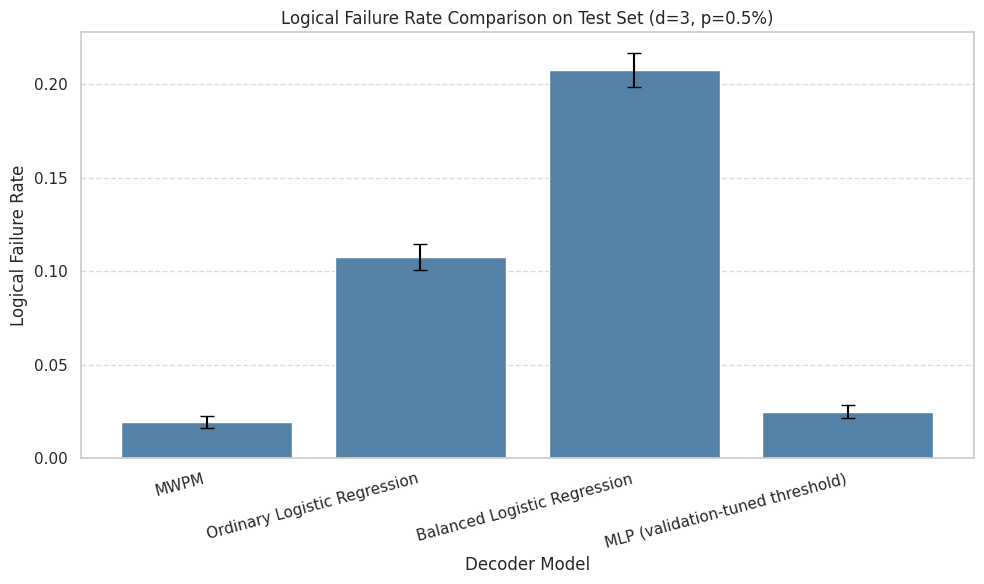

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plotting style
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

# Create a bar plot of logical failure rates with 95% Wilson confidence intervals
x_coords = range(len(comparison_df))
y_values = comparison_df['Logical failure rate']
y_err_lower = comparison_df['Logical failure rate'] - comparison_df['95% CI low']
y_err_upper = comparison_df['95% CI high'] - comparison_df['Logical failure rate']
yerr = [y_err_lower.values, y_err_upper.values]

# Plot the bars
ax = sns.barplot(
    data=comparison_df,
    x='Decoder',
    y='Logical failure rate',
    color='steelblue'
)

# Add the error bars manually
plt.errorbar(
    x=x_coords,
    y=y_values,
    yerr=yerr,
    fmt='none',
    c='black',
    capsize=5,
    label='95% Wilson CI'
)

plt.title('Logical Failure Rate Comparison on Test Set (d=3, p=0.5%)')
plt.ylabel('Logical Failure Rate')
plt.xlabel('Decoder Model')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [22]:
# Save the real test predictions and metadata; do not hardcode failure counts.
import json, platform, sklearn
from pathlib import Path

np.savez(
    'decoder_comparison_d3_test.npz',
    test_detectors=X_test,
    observables=actual_test,
    mwpm_predictions=mwpm_test_pred,
    logistic_regression_predictions=lr_test_pred,
    balanced_logistic_regression_predictions=lr_balanced_test_pred,
    mlp_predictions=mlp_test_pred,
    mlp_probabilities=mlp_test_prob,
)

metadata = {
    'code_distance': DISTANCE,
    'syndrome_rounds': ROUNDS,
    'physical_error_rate': TRAINING_NOISE_RATE,
    'dataset_shots': DATASET_SHOTS,
    'train_shots': int(len(X_train)),
    'validation_shots': int(len(X_val)),
    'test_shots': int(len(X_test)),
    'random_seed': SEED,
    'detectors': int(circuit.num_detectors),
    'observables': int(circuit.num_observables),
    'mlp_threshold_selected_on_validation': float(FINAL_THRESHOLD),
    'python_version': platform.python_version(),
    'numpy_version': np.__version__,
    'scikit_learn_version': sklearn.__version__,
    'results': [
        {
            'decoder': row['Decoder'],
            'logical_failures': int(row['Logical failures']),
            'test_shots': int(row['Test shots']),
            'logical_failure_rate': float(row['Logical failure rate']),
            'wilson_95_ci': [float(row['95% CI low']), float(row['95% CI high'])],
        }
        for row in comparison_rows
    ],
}
with open('decoder_comparison_d3_test.json', 'w') as f:
    json.dump(metadata, f, indent=2)
print('Saved decoder_comparison_d3_test.npz and decoder_comparison_d3_test.json')
print(json.dumps(metadata, indent=2))


Saved decoder_comparison_d3_test.npz and decoder_comparison_d3_test.json
{
  "code_distance": 3,
  "syndrome_rounds": 3,
  "physical_error_rate": 0.005,
  "dataset_shots": 50000,
  "train_shots": 35000,
  "validation_shots": 7500,
  "test_shots": 7500,
  "random_seed": 42,
  "detectors": 24,
  "observables": 1,
  "mlp_threshold_selected_on_validation": 0.5499999999999999,
  "python_version": "3.13.18",
  "numpy_version": "2.1.3",
  "scikit_learn_version": "1.6.1",
  "results": [
    {
      "decoder": "MWPM",
      "logical_failures": 144,
      "test_shots": 7500,
      "logical_failure_rate": 0.0192,
      "wilson_95_ci": [
        0.016331451329138214,
        0.022560840853575237
      ]
    },
    {
      "decoder": "Ordinary Logistic Regression",
      "logical_failures": 807,
      "test_shots": 7500,
      "logical_failure_rate": 0.1076,
      "wilson_95_ci": [
        0.10078668627158634,
        0.1148150929557364
      ]
    },
    {
      "decoder": "Balanced Logistic Regre

In [23]:
from scipy.stats import binomtest

# A shot is a decoder failure when its predicted logical observable differs from truth.
mwpm_failed = (np.asarray(mwpm_test_pred).reshape(-1) != np.asarray(actual_test).reshape(-1))
mlp_failed = (np.asarray(mlp_test_pred).reshape(-1) != np.asarray(actual_test).reshape(-1))
assert len(mwpm_failed) == len(mlp_failed)

# Discordant shots: only one of the two decoders fails.
mwpm_only_fails = int(np.sum(mwpm_failed & ~mlp_failed))
mlp_only_fails = int(np.sum(~mwpm_failed & mlp_failed))
discordant = mwpm_only_fails + mlp_only_fails

print('Shots where MWPM fails but MLP succeeds:', mwpm_only_fails)
print('Shots where MLP fails but MWPM succeeds:', mlp_only_fails)
print('Total discordant shots:', discordant)
if discordant == 0:
    print('No discordant shots: the paired test has no evidence to evaluate.')
else:
    test = binomtest(k=mlp_only_fails, n=discordant, p=0.5, alternative='two-sided')
    print('Exact paired binomial/McNemar-equivalent p-value:', test.pvalue)
    print('Interpretation: a small p-value (commonly < 0.05) suggests the decoders differ in failure probability on this test set.')
print('MWPM failure rate:', float(mwpm_failed.mean()))
print('MLP failure rate:', float(mlp_failed.mean()))


Shots where MWPM fails but MLP succeeds: 56
Shots where MLP fails but MWPM succeeds: 98
Total discordant shots: 154
Exact paired binomial/McNemar-equivalent p-value: 0.0008935310594584625
Interpretation: a small p-value (commonly < 0.05) suggests the decoders differ in failure probability on this test set.
MWPM failure rate: 0.0192
MLP failure rate: 0.0248


In [24]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

REPEAT_SEEDS = [101, 202, 303, 404, 505]
REPEAT_SHOTS = 30000  # lower to 10000 for a quick test run
REPEAT_P = TRAINING_NOISE_RATE

seed_rows = []
for repeat_seed in REPEAT_SEEDS:
    print(f'\nRunning independent seed {repeat_seed}...')
    c = make_surface_code_circuit(REPEAT_P, distance=DISTANCE, rounds=ROUNDS)
    s = c.compile_detector_sampler(seed=repeat_seed)
    det, obs = s.sample(shots=REPEAT_SHOTS, separate_observables=True)
    det = np.asarray(det, dtype=np.uint8)
    obs = np.asarray(obs, dtype=np.uint8).reshape(-1)

    ids = np.arange(REPEAT_SHOTS)
    tr, tmp = train_test_split(ids, test_size=0.30, random_state=repeat_seed, stratify=obs)
    va, te = train_test_split(tmp, test_size=0.50, random_state=repeat_seed + 1, stratify=obs[tmp])
    Xtr, ytr = det[tr], obs[tr]
    Xva, yva = det[va], obs[va]
    Xte, yte = det[te], obs[te]

    dem_seed = c.detector_error_model(decompose_errors=True)
    dec_seed = pymatching.Matching.from_detector_error_model(dem_seed)
    pred_mwpm = np.asarray(dec_seed.decode_batch(Xte), dtype=np.uint8).reshape(-1)

    mlp_seed = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
                      alpha=0.001, max_iter=300, early_stopping=False,
                      random_state=repeat_seed)
    )
    mlp_seed.fit(Xtr, ytr)
    pva = mlp_seed.predict_proba(Xva)[:, 1]
    candidates = np.arange(0.10, 0.901, 0.025)
    # Deterministic tie-break: closest to 0.5 among thresholds with the same validation error.
    threshold = min(candidates, key=lambda t: (np.mean((pva >= t).astype(np.uint8) != yva), abs(t - 0.5)))
    pte = mlp_seed.predict_proba(Xte)[:, 1]
    pred_mlp = (pte >= threshold).astype(np.uint8)

    fail_mwpm = int(np.sum(pred_mwpm != yte))
    fail_mlp = int(np.sum(pred_mlp != yte))
    seed_rows.append({
        'seed': repeat_seed, 'train_shots': len(tr), 'validation_shots': len(va),
        'test_shots': len(te), 'mlp_threshold': float(threshold),
        'mwpm_failures': fail_mwpm, 'mwpm_rate': fail_mwpm / len(te),
        'mlp_failures': fail_mlp, 'mlp_rate': fail_mlp / len(te),
    })
    print(f'MWPM {fail_mwpm}/{len(te)} ({fail_mwpm/len(te):.3%}); MLP {fail_mlp}/{len(te)} ({fail_mlp/len(te):.3%}); threshold={threshold:.3f}')

seed_results_df = pd.DataFrame(seed_rows)
display(seed_results_df)
print('\nAcross-seed mean failure rates:')
display(seed_results_df[['mwpm_rate', 'mlp_rate']].agg(['mean', 'std', 'min', 'max']))
seed_results_df.to_csv('independent_seed_results.csv', index=False)
print('Saved independent_seed_results.csv')



Running independent seed 101...
MWPM 88/4500 (1.956%); MLP 143/4500 (3.178%); threshold=0.225

Running independent seed 202...
MWPM 73/4500 (1.622%); MLP 120/4500 (2.667%); threshold=0.500

Running independent seed 303...
MWPM 96/4500 (2.133%); MLP 144/4500 (3.200%); threshold=0.725

Running independent seed 404...
MWPM 101/4500 (2.244%); MLP 133/4500 (2.956%); threshold=0.600

Running independent seed 505...
MWPM 78/4500 (1.733%); MLP 128/4500 (2.844%); threshold=0.475


,seed,train_shots,validation_shots,test_shots,mlp_threshold,mwpm_failures,mwpm_rate,mlp_failures,mlp_rate
0,101,21000,4500,4500,0.225,88,0.019556,143,0.031778
1,202,21000,4500,4500,0.500,73,0.016222,120,0.026667
2,303,21000,4500,4500,0.725,96,0.021333,144,0.032000
3,404,21000,4500,4500,0.600,101,0.022444,133,0.029556
4,505,21000,4500,4500,0.475,78,0.017333,128,0.028444



Across-seed mean failure rates:


,mwpm_rate,mlp_rate
mean,0.019378,0.029689
std,0.002617,0.002259
min,0.016222,0.026667
max,0.022444,0.032000


Saved independent_seed_results.csv


In [25]:
# Use Colab's interactive formatter when available; otherwise display the DataFrame normally.
try:
    from google.colab import data_table
    data_table.enable_dataframe_formatter()
except (ImportError, AttributeError, ModuleNotFoundError):
    pass

display(seed_results_df)


,seed,train_shots,validation_shots,test_shots,mlp_threshold,mwpm_failures,mwpm_rate,mlp_failures,mlp_rate
0,101,21000,4500,4500,0.225,88,0.019556,143,0.031778
1,202,21000,4500,4500,0.500,73,0.016222,120,0.026667
2,303,21000,4500,4500,0.725,96,0.021333,144,0.032000
3,404,21000,4500,4500,0.600,101,0.022444,133,0.029556
4,505,21000,4500,4500,0.475,78,0.017333,128,0.028444


/tmp/ipykernel_1852/3592181403.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1852/3592181403.py:30: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


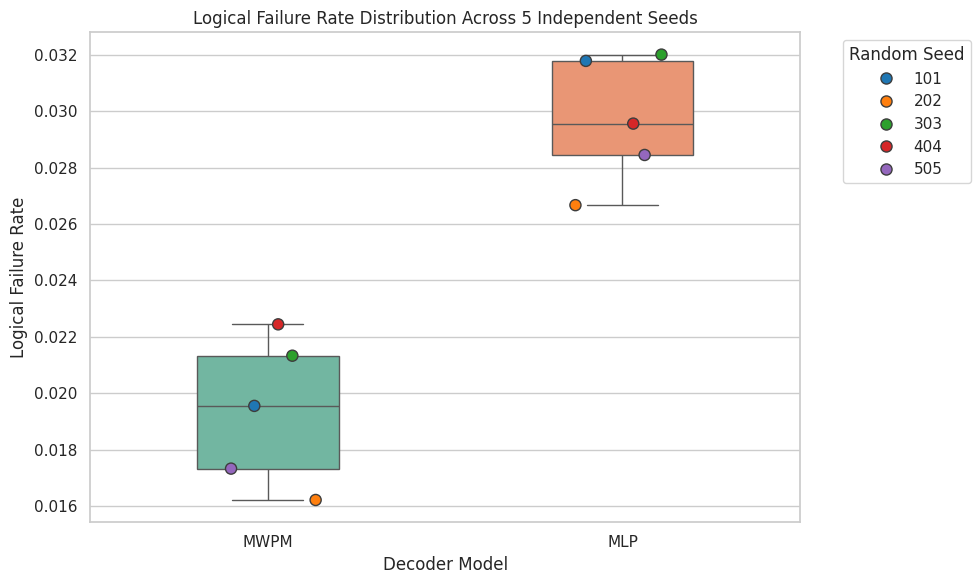

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set theme
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

# Reshape seed_results_df to long format for easier plotting with seaborn
seed_melted = seed_results_df.melt(
    id_vars=['seed', 'mlp_threshold'],
    value_vars=['mwpm_rate', 'mlp_rate'],
    var_name='Decoder',
    value_name='Logical Failure Rate'
)
seed_melted['Decoder'] = seed_melted['Decoder'].map({
    'mwpm_rate': 'MWPM',
    'mlp_rate': 'MLP'
})

# Plot individual run comparisons and distribution
sns.boxplot(
    data=seed_melted,
    x='Decoder',
    y='Logical Failure Rate',
    palette='Set2',
    width=0.4,
    showfliers=False
)

sns.stripplot(
    data=seed_melted,
    x='Decoder',
    y='Logical Failure Rate',
    hue='seed',
    palette='tab10',
    size=8,
    jitter=0.15,
    linewidth=1,
    edgecolor='gray'
)

plt.title('Logical Failure Rate Distribution Across 5 Independent Seeds')
plt.ylabel('Logical Failure Rate')
plt.xlabel('Decoder Model')
plt.legend(title='Random Seed', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [27]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

GRID_DISTANCES = [3, 5, 7, 9]
GRID_ERROR_RATES = [0.001, 0.005, 0.01]
GRID_SHOTS = 30000  # pilot run; use more shots for final estimates
GRID_SEEDs = [1001, 2202, 3303, 4004]
grid_rows = []

for d in GRID_DISTANCES:
    for p in GRID_ERROR_RATES:
        for grid_seed in GRID_SEEDs:
            print(f'\nGrid run: distance={d}, rounds={d}, p={p:.3%}, seed={grid_seed}')
            c = make_surface_code_circuit(p, distance=d, rounds=d)
            s = c.compile_detector_sampler(seed=grid_seed)
            det, obs = s.sample(shots=GRID_SHOTS, separate_observables=True)
            det = np.asarray(det, dtype=np.uint8)
            obs = np.asarray(obs, dtype=np.uint8).reshape(-1)

            ids = np.arange(GRID_SHOTS)
            tr, tmp = train_test_split(ids, test_size=0.30, random_state=grid_seed, stratify=obs)
            va, te = train_test_split(tmp, test_size=0.50, random_state=grid_seed + 1, stratify=obs[tmp])
            Xtr, ytr = det[tr], obs[tr]
            Xva, yva = det[va], obs[va]
            Xte, yte = det[te], obs[te]

            decoder = pymatching.Matching.from_detector_error_model(
                c.detector_error_model(decompose_errors=True)
            )
            pred_mwpm = np.asarray(decoder.decode_batch(Xte), dtype=np.uint8).reshape(-1)

            model = make_pipeline(
                StandardScaler(),
                MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
                              alpha=0.001, max_iter=250, early_stopping=False, random_state=grid_seed)
            )
            model.fit(Xtr, ytr)
            val_prob = model.predict_proba(Xva)[:, 1]
            thresholds = np.arange(0.10, 0.901, 0.025)
            best_threshold = min(
                thresholds,
                key=lambda t: (np.mean((val_prob >= t).astype(np.uint8) != yva), abs(t - 0.5))
            )
            test_prob = model.predict_proba(Xte)[:, 1]
            pred_mlp = (test_prob >= best_threshold).astype(np.uint8)

            mwpm_fail = int(np.sum(pred_mwpm != yte))
            mlp_fail = int(np.sum(pred_mlp != yte))
            grid_rows.append({
                'distance': d, 'rounds': d, 'physical_error_rate': p, 'seed': grid_seed,
                'shots_total': GRID_SHOTS, 'test_shots': len(te),
                'mwpm_failures': mwpm_fail, 'mwpm_failure_rate': mwpm_fail / len(te),
                'mlp_failures': mlp_fail, 'mlp_failure_rate': mlp_fail / len(te),
                'mlp_threshold_validation': float(best_threshold),
            })
            print(f'MWPM={mwpm_fail/len(te):.3%}; MLP={mlp_fail/len(te):.3%}; threshold={best_threshold:.3f}')

grid_results_df = pd.DataFrame(grid_rows)
display(grid_results_df)
grid_results_df.to_csv('distance_noise_grid_results.csv', index=False)
print('Saved distance_noise_grid_results.csv')


Grid run: distance=3, rounds=3, p=0.100%, seed=1001
MWPM=0.133%; MLP=0.311%; threshold=0.400

Grid run: distance=3, rounds=3, p=0.100%, seed=2202
MWPM=0.244%; MLP=0.356%; threshold=0.500

Grid run: distance=3, rounds=3, p=0.100%, seed=3303
MWPM=0.089%; MLP=0.156%; threshold=0.425

Grid run: distance=3, rounds=3, p=0.100%, seed=4004
MWPM=0.111%; MLP=0.222%; threshold=0.275

Grid run: distance=3, rounds=3, p=0.500%, seed=1001
MWPM=1.711%; MLP=2.600%; threshold=0.475

Grid run: distance=3, rounds=3, p=0.500%, seed=2202
MWPM=1.956%; MLP=2.778%; threshold=0.900

Grid run: distance=3, rounds=3, p=0.500%, seed=3303
MWPM=1.911%; MLP=2.911%; threshold=0.700

Grid run: distance=3, rounds=3, p=0.500%, seed=4004
MWPM=1.889%; MLP=2.556%; threshold=0.650

Grid run: distance=3, rounds=3, p=1.000%, seed=1001


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (250) reached and the optimization hasn't converged yet.
  warnings.warn(


MWPM=6.511%; MLP=9.644%; threshold=0.525

Grid run: distance=3, rounds=3, p=1.000%, seed=2202
MWPM=6.200%; MLP=8.778%; threshold=0.675

Grid run: distance=3, rounds=3, p=1.000%, seed=3303


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (250) reached and the optimization hasn't converged yet.
  warnings.warn(


MWPM=6.689%; MLP=9.067%; threshold=0.825

Grid run: distance=3, rounds=3, p=1.000%, seed=4004


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (250) reached and the optimization hasn't converged yet.
  warnings.warn(


MWPM=6.200%; MLP=8.889%; threshold=0.650

Grid run: distance=5, rounds=5, p=0.100%, seed=1001
MWPM=0.000%; MLP=2.178%; threshold=0.575

Grid run: distance=5, rounds=5, p=0.100%, seed=2202
MWPM=0.000%; MLP=1.711%; threshold=0.575

Grid run: distance=5, rounds=5, p=0.100%, seed=3303
MWPM=0.000%; MLP=2.156%; threshold=0.400

Grid run: distance=5, rounds=5, p=0.100%, seed=4004
MWPM=0.022%; MLP=2.222%; threshold=0.325

Grid run: distance=5, rounds=5, p=0.500%, seed=1001
MWPM=1.422%; MLP=21.044%; threshold=0.900

Grid run: distance=5, rounds=5, p=0.500%, seed=2202
MWPM=2.022%; MLP=20.822%; threshold=0.825

Grid run: distance=5, rounds=5, p=0.500%, seed=3303
MWPM=1.556%; MLP=20.600%; threshold=0.900

Grid run: distance=5, rounds=5, p=0.500%, seed=4004
MWPM=1.356%; MLP=19.467%; threshold=0.900

Grid run: distance=5, rounds=5, p=1.000%, seed=1001
MWPM=10.089%; MLP=40.422%; threshold=0.900

Grid run: distance=5, rounds=5, p=1.000%, seed=2202
MWPM=10.044%; MLP=38.133%; threshold=0.900

Grid run: 

,distance,rounds,physical_error_rate,seed,shots_total,test_shots,mwpm_failures,mwpm_failure_rate,mlp_failures,mlp_failure_rate,mlp_threshold_validation
0,3,3,0.001,1001,30000,4500,6,0.001333,14,0.003111,0.400
1,3,3,0.001,2202,30000,4500,11,0.002444,16,0.003556,0.500
2,3,3,0.001,3303,30000,4500,4,0.000889,7,0.001556,0.425
3,3,3,0.001,4004,30000,4500,5,0.001111,10,0.002222,0.275
4,3,3,0.005,1001,30000,4500,77,0.017111,117,0.026000,0.475
5,3,3,0.005,2202,30000,4500,88,0.019556,125,0.027778,0.900
6,3,3,0.005,3303,30000,4500,86,0.019111,131,0.029111,0.700
7,3,3,0.005,4004,30000,4500,85,0.018889,115,0.025556,0.650
8,3,3,0.010,1001,30000,4500,293,0.065111,434,0.096444,0.525
9,3,3,0.010,2202,30000,4500,279,0.062000,395,0.087778,0.675


Saved distance_noise_grid_results.csv


In [28]:
# Optional Google Colab interactive sheet; fall back to a normal table elsewhere.
try:
    from google.colab import sheets
    sheet = sheets.InteractiveSheet(df=grid_results_df)
except (ImportError, AttributeError, ModuleNotFoundError):
    display(grid_results_df)


https://docs.google.com/spreadsheets/d/1M1ZIC2ALbpqf7fz_HQ411DQuJpI_5q27z0UJy2taurA/edit#gid=0


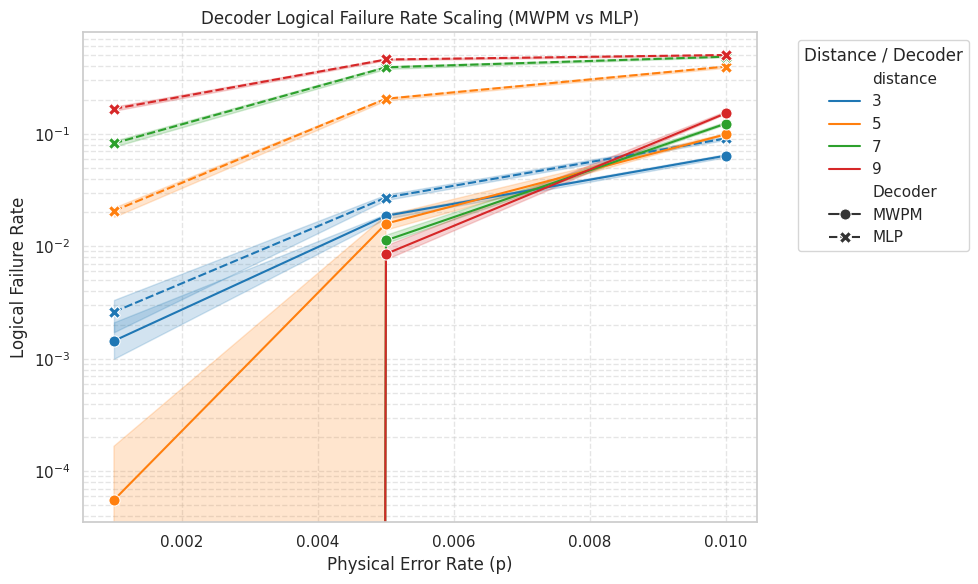

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plotting style
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 6))

# Reshape grid_results_df to long format for easier comparative plotting
grid_melted = grid_results_df.melt(
    id_vars=['distance', 'physical_error_rate'],
    value_vars=['mwpm_failure_rate', 'mlp_failure_rate'],
    var_name='Decoder',
    value_name='Logical Failure Rate'
)
grid_melted['Decoder'] = grid_melted['Decoder'].map({
    'mwpm_failure_rate': 'MWPM',
    'mlp_failure_rate': 'MLP'
})

# Plot the line trends with markers for each code distance and decoder type
sns.lineplot(
    data=grid_melted,
    x='physical_error_rate',
    y='Logical Failure Rate',
    hue='distance',
    style='Decoder',
    markers=True,
    dashes=True,
    palette='tab10',
    markersize=8
)

plt.title('Decoder Logical Failure Rate Scaling (MWPM vs MLP)')
plt.xlabel('Physical Error Rate (p)')
plt.ylabel('Logical Failure Rate')
plt.yscale('log')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(title='Distance / Decoder', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [30]:
import time

# Warm up once so first-call overhead is not the only thing being measured.
_ = mwpm_decoder.decode_batch(X_test[:min(100, len(X_test))])
_ = mlp_model.predict_proba(X_test[:min(100, len(X_test))])

def benchmark_batch(fn, repeats=7):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return {
        'median_seconds_per_batch': float(np.median(times)),
        'mean_seconds_per_batch': float(np.mean(times)),
        'std_seconds_per_batch': float(np.std(times, ddof=1)) if len(times) > 1 else 0.0,
    }

N_BENCH = len(X_test)
mwpm_timing = benchmark_batch(lambda: mwpm_decoder.decode_batch(X_test))
mlp_timing = benchmark_batch(lambda: mlp_model.predict_proba(X_test))

speed_rows = []
for name, timing in [('MWPM', mwpm_timing), ('MLP probability inference', mlp_timing)]:
    speed_rows.append({
        'decoder': name, **timing,
        'test_batch_size': N_BENCH,
        'median_microseconds_per_shot': timing['median_seconds_per_batch'] * 1e6 / N_BENCH,
        'shots_per_second': N_BENCH / timing['median_seconds_per_batch'],
    })
speed_df = pd.DataFrame(speed_rows)
display(speed_df)
speed_df.to_csv('decoding_speed_results.csv', index=False)
print('Saved decoding_speed_results.csv')
print('Note: MLP timing includes predict_proba; it does not include thresholding, which is negligible but can be timed separately if desired.')


,decoder,median_seconds_per_batch,mean_seconds_per_batch,std_seconds_per_batch,test_batch_size,median_microseconds_per_shot,shots_per_second
0,MWPM,0.002343,0.002843,0.000938,7500,0.312367,3.201366e+06
1,MLP probability inference,0.004503,0.005532,0.002704,7500,0.600449,1.665419e+06


Saved decoding_speed_results.csv
Note: MLP timing includes predict_proba; it does not include thresholding, which is negligible but can be timed separately if desired.


In [31]:
# Optional Google Colab interactive sheet; fall back to a normal table elsewhere.
try:
    from google.colab import sheets
    sheet = sheets.InteractiveSheet(df=speed_df)
except (ImportError, AttributeError, ModuleNotFoundError):
    display(speed_df)


https://docs.google.com/spreadsheets/d/1ZmAOyWkeBi1sOZiNxS67EKgu61yTzCJyWNTgnPXPMFw/edit#gid=0


Using original 'speed_df' from memory.


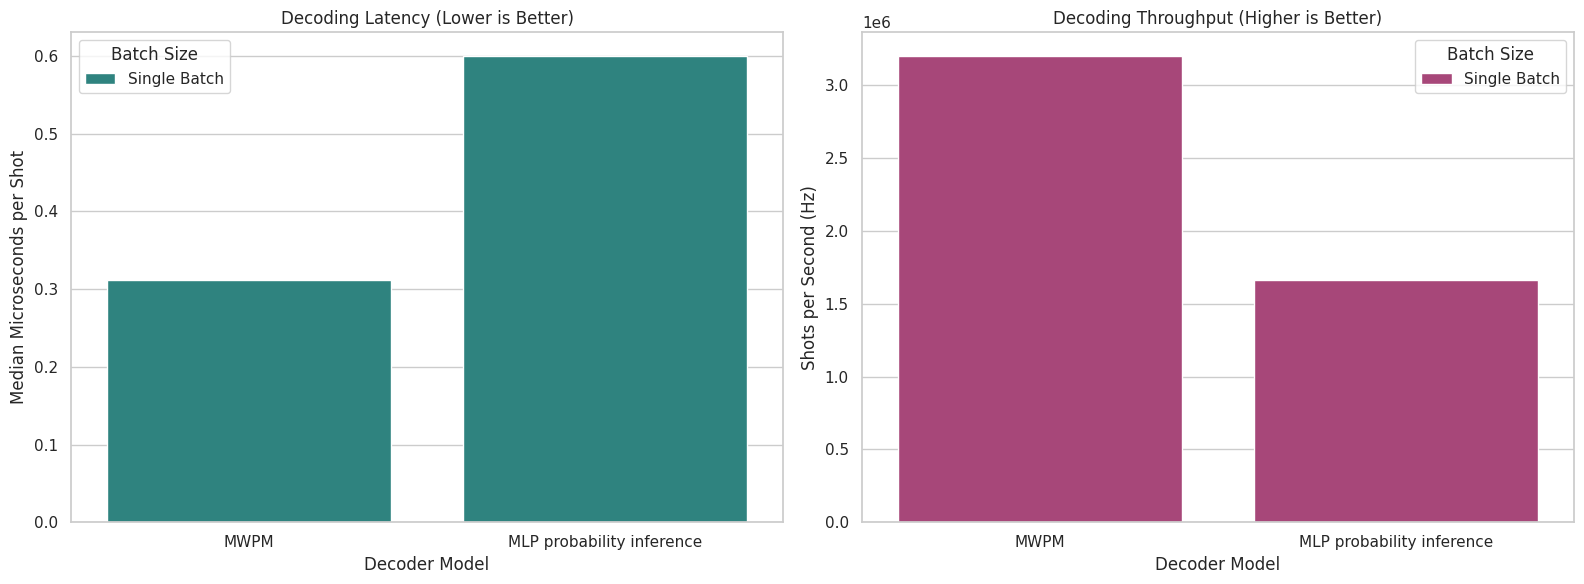

In [32]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

speed_df_improved = globals().get('speed_df_improved', None)

# Fallback 1: Load improved results from CSV if not in memory
if speed_df_improved is None:
    csv_path = 'improved_decoding_speed_results.csv'
    if os.path.exists(csv_path):
        print(f"'speed_df_improved' not found in memory. Loading from '{csv_path}'...")
        speed_df_improved = pd.read_csv(csv_path)

# Fallback 2: Load original benchmarking results if improved results are missing
if speed_df_improved is None:
    original_df = globals().get('speed_df', None)
    if original_df is not None:
        print("Using original 'speed_df' from memory.")
        speed_df_improved = original_df.copy()
    else:
        orig_csv_path = 'decoding_speed_results.csv'
        if os.path.exists(orig_csv_path):
            print(f"Loading original results from '{orig_csv_path}'...")
            speed_df_improved = pd.read_csv(orig_csv_path)

# If no data is available at all, guide the user on how to generate it
if speed_df_improved is None:
    print("\n[!] ERROR: Cannot generate speed charts.")
    print("No benchmarking data was found in memory or on disk.")
    print("\nHow to fix this:")
    print("1. Run cell 'iQiSlMrqTKyy' to calculate the decoding speed metrics.")
    print("2. Run this plotting cell again.\n")
else:
    # Map column names if they are from the older schema
    plot_data = speed_df_improved.copy()
    if 'median_us_per_shot' in plot_data.columns:
        plot_data = plot_data.rename(columns={'median_us_per_shot': 'median_microseconds_per_shot'})

    # If the original schema did not contain 'batch_size', assign a default one for plotting
    if 'batch_size' not in plot_data.columns:
        plot_data['batch_size'] = 'Single Batch'

    # Set the plotting style
    sns.set_theme(style='whitegrid')
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Plot 1: Microseconds per shot (Lower is better)
    sns.barplot(
        data=plot_data,
        x='decoder',
        y='median_microseconds_per_shot',
        hue='batch_size',
        ax=axes[0],
        palette='viridis'
    )
    axes[0].set_title('Decoding Latency (Lower is Better)')
    axes[0].set_ylabel('Median Microseconds per Shot')
    axes[0].set_xlabel('Decoder Model')
    axes[0].legend(title='Batch Size')

    # Plot 2: Shots per second (Higher is better)
    sns.barplot(
        data=plot_data,
        x='decoder',
        y='shots_per_second',
        hue='batch_size',
        ax=axes[1],
        palette='magma'
    )
    axes[1].set_title('Decoding Throughput (Higher is Better)')
    axes[1].set_ylabel('Shots per Second (Hz)')
    axes[1].set_xlabel('Decoder Model')
    axes[1].legend(title='Batch Size')

    plt.tight_layout()
    plt.show()

In [33]:
import pandas as pd

grid_df = pd.DataFrame(grid_rows)

required = {
    "distance", "physical_error_rate", "seed",
    "mwpm_failures", "mlp_failures", "test_shots"
}
assert required.issubset(grid_df.columns), (
    f"Missing columns: {required - set(grid_df.columns)}"
)

grid_df["mwpm_rate"] = (
    grid_df["mwpm_failures"] / grid_df["test_shots"]
)
grid_df["mlp_rate"] = (
    grid_df["mlp_failures"] / grid_df["test_shots"]
)

# Save the individual runs before aggregation.
grid_df.to_csv("improved_distance_noise_runs.csv", index=False)

summary = (
    grid_df.groupby(["distance", "physical_error_rate"])
    .agg(
        seeds=("seed", "nunique"),
        mean_mwpm_rate=("mwpm_rate", "mean"),
        std_mwpm_rate=("mwpm_rate", "std"),
        mean_mlp_rate=("mlp_rate", "mean"),
        std_mlp_rate=("mlp_rate", "std"),
        total_test_shots=("test_shots", "sum"),
    )
    .reset_index()
)

display(summary)
summary.to_csv("improved_distance_noise_summary.csv", index=False)

,distance,physical_error_rate,seeds,mean_mwpm_rate,std_mwpm_rate,mean_mlp_rate,std_mlp_rate,total_test_shots
0,3,0.001,4,0.001444,0.000691,0.002611,0.000896,18000
1,3,0.005,4,0.018667,0.001073,0.027111,0.001643,18000
2,3,0.010,4,0.064000,0.002421,0.090944,0.003855,18000
3,5,0.001,4,0.000056,0.000111,0.020667,0.002387,18000
4,5,0.005,4,0.015889,0.003006,0.204833,0.007016,18000
5,5,0.010,4,0.099000,0.001942,0.396333,0.010351,18000
6,7,0.001,4,0.000000,0.000000,0.082278,0.005730,18000
7,7,0.005,4,0.011278,0.001236,0.389833,0.012328,18000
8,7,0.010,4,0.123333,0.004247,0.484556,0.006339,18000
9,9,0.001,4,0.000000,0.000000,0.166667,0.009012,18000


In [34]:
# Optional Google Colab interactive sheet; fall back to a normal table elsewhere.
try:
    from google.colab import sheets
    sheet = sheets.InteractiveSheet(df=summary)
except (ImportError, AttributeError, ModuleNotFoundError):
    display(summary)


https://docs.google.com/spreadsheets/d/1y87i25-zwDgnO_hzRx8Y_fh8uRTWM89aUyr4y7HLsIg/edit#gid=0


In [35]:
import time
import numpy as np
import pandas as pd

# Test multiple batch sizes, up to the available held-out test set.
batch_sizes = sorted(set(
    n for n in [1, 16, 64, 256, 1024, len(X_test)]
    if n <= len(X_test)
))

def predict_mwpm(batch):
    return np.asarray(
        mwpm_decoder.decode_batch(batch)
    ).reshape(-1)

def predict_mlp(batch):
    probabilities = mlp_model.predict_proba(batch)[:, 1]
    return (probabilities >= FINAL_THRESHOLD).astype(np.uint8)

# Warm up both models before measuring.
_ = predict_mwpm(X_test[:min(100, len(X_test))])
_ = predict_mlp(X_test[:min(100, len(X_test))])

speed_rows = []

for batch_size in batch_sizes:
    batch = X_test[:batch_size]

    for name, predict_fn in [
        ("MWPM", predict_mwpm),
        ("MLP", predict_mlp),
    ]:
        # More repeats for small batches; fewer for large batches.
        repeats = 100 if batch_size <= 64 else 20
        times = []

        for _ in range(repeats):
            start = time.perf_counter()
            predictions = predict_fn(batch)
            elapsed = time.perf_counter() - start
            times.append(elapsed)

        median_seconds = float(np.median(times))

        speed_rows.append({
            "decoder": name,
            "batch_size": batch_size,
            "repeats": repeats,
            "median_batch_ms": median_seconds * 1000,
            "median_us_per_shot": (
                median_seconds * 1e6 / batch_size
            ),
            "shots_per_second": batch_size / median_seconds,
        })

speed_df_improved = pd.DataFrame(speed_rows)
display(speed_df_improved)

speed_df_improved.to_csv(
    "improved_decoding_speed_results.csv", index=False
)

,decoder,batch_size,repeats,median_batch_ms,median_us_per_shot,shots_per_second
0,MWPM,1,100,0.005320,5.320000,1.879699e+05
1,MLP,1,100,0.503700,503.700500,1.985307e+03
2,MWPM,16,100,0.009575,0.598469,1.670931e+06
3,MLP,16,100,0.437354,27.334656,3.658360e+04
4,MWPM,64,100,0.029770,0.465156,2.149815e+06
5,MLP,64,100,0.468160,7.315000,1.367054e+05
6,MWPM,256,20,0.109800,0.428906,2.331512e+06
7,MLP,256,20,0.710995,2.777324,3.600588e+05
8,MWPM,1024,20,0.475670,0.464521,2.152753e+06
9,MLP,1024,20,2.855319,2.788398,3.586289e+05


In [36]:
# Optional Google Colab interactive sheet; fall back to a normal table elsewhere.
try:
    from google.colab import sheets
    sheet = sheets.InteractiveSheet(df=speed_df_improved)
except (ImportError, AttributeError, ModuleNotFoundError):
    display(speed_df_improved)


https://docs.google.com/spreadsheets/d/1BI_7MKFiULQY8YmX1m1AzneHl8S6Z0qtkWfEHxbgl6I/edit#gid=0
